# DSC 411/511 - Lecture 05
# Classification I: Decision Trees and Naive Bayes

**Primary dataset:** Ames Housing (De Cock, 2011)
**Secondary datasets:** a spam message corpus (built in this notebook) and
Breast Cancer Wisconsin (built into scikit-learn)




---
# Section 0: Setup

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 42
print('ready')

ready


In [4]:
DATA_path= "/Users/home/workspace/School/DataMining/DataMining/class_workbooks/datasets/AmesHousing.csv"

df = pd.read_csv(DATA_path)

print('Rows:', df.shape[0])
print('Columns:', df.shape[1])

Rows: 2930
Columns: 82


---
# Section 1: From a Number to a Category

Every algorithm today predicts a **category**. `SalePrice` is a number.
So the first job is to decide what question we are actually asking.

### The question

> A property assessor has to place each house in a price band before the
> valuation is finalised. Given everything else about the house, is it
> **above or below the market median**?

Real decision. Balanced classes. Answerable from the columns we have.

In [5]:
median_price = df['SalePrice'].median()
df['Expensive'] = (df['SalePrice'] > median_price).astype(int)

print(f'Median SalePrice : ${median_price:,.0f}')
print()
print(df['Expensive'].value_counts().rename({0: 'Below median (0)', 1: 'Above median (1)'}))
print()
print('Class balance:')
print((df['Expensive'].value_counts(normalize=True) * 100).round(1))

Median SalePrice : $160,000

Expensive
Below median (0)    1467
Above median (1)    1463
Name: count, dtype: int64

Class balance:
Expensive
0    50.1
1    49.9
Name: proportion, dtype: float64


**Why a balanced target matters right now.** If 95 percent of rows were one class,
a model that always guesses that class scores 95 percent and has learned nothing.
Handling imbalance is the Sep 21 lecture. Today we avoid the problem.

In [6]:
# Pick the feature columns. Numeric only, so both algorithms can read them.
DROP = ['Order', 'PID', 'SalePrice', 'Expensive']
num = df.select_dtypes(include='number').drop(columns=[c for c in DROP if c in df.columns])

X = num.fillna(num.median())
y = df['Expensive']

print('Features :', X.shape[1])
print('Rows     :', X.shape[0])
print('Target   : Expensive (0 or 1)')
print()
print('CRITICAL: SalePrice is NOT in X.')
print('If it were, the model would score 100% and learn nothing. That is leakage.')
print('SalePrice in X?', 'SalePrice' in X.columns)

Features : 36
Rows     : 2930
Target   : Expensive (0 or 1)

CRITICAL: SalePrice is NOT in X.
If it were, the model would score 100% and learn nothing. That is leakage.
SalePrice in X? False


---
# Section 2: Train and Test

You cannot judge a model on the rows it learned from. It has seen the answers.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)

print(f'Training rows : {len(X_train):,}')
print(f'Test rows     : {len(X_test):,}')
print()
print('stratify=y keeps the class balance the same in both halves:')
print(f'   train: {y_train.mean()*100:.1f}% above median')
print(f'   test : {y_test.mean()*100:.1f}% above median')
print()
print(f'random_state={SEED} makes this reproducible. Always state your seed.')

Training rows : 2,197
Test rows     : 733

stratify=y keeps the class balance the same in both halves:
   train: 49.9% above median
   test : 49.9% above median

random_state=42 makes this reproducible. Always state your seed.


In [8]:
# The baseline you must beat. Always guess the most common class.
baseline = max(y_test.mean(), 1 - y_test.mean())
print(f'Baseline accuracy (always guess the majority): {baseline*100:.1f}%')
print()
print('Any model that cannot beat this has learned nothing.')

Baseline accuracy (always guess the majority): 50.1%

Any model that cannot beat this has learned nothing.


---
# Section 3: Decision Tree on Ames

Ask a series of yes/no questions until you reach an answer.

In [9]:
tree = DecisionTreeClassifier(max_depth=3, random_state=SEED)
tree.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree.predict(X_train))
test_acc  = accuracy_score(y_test,  tree.predict(X_test))

print(f'Training accuracy : {train_acc*100:.1f}%')
print(f'Test accuracy     : {test_acc*100:.1f}%')
print(f'Baseline          : {baseline*100:.1f}%')

Training accuracy : 89.2%
Test accuracy     : 87.6%
Baseline          : 50.1%


## 3.1 What the tree actually learned

This is the whole reason to use a tree. You can read it.

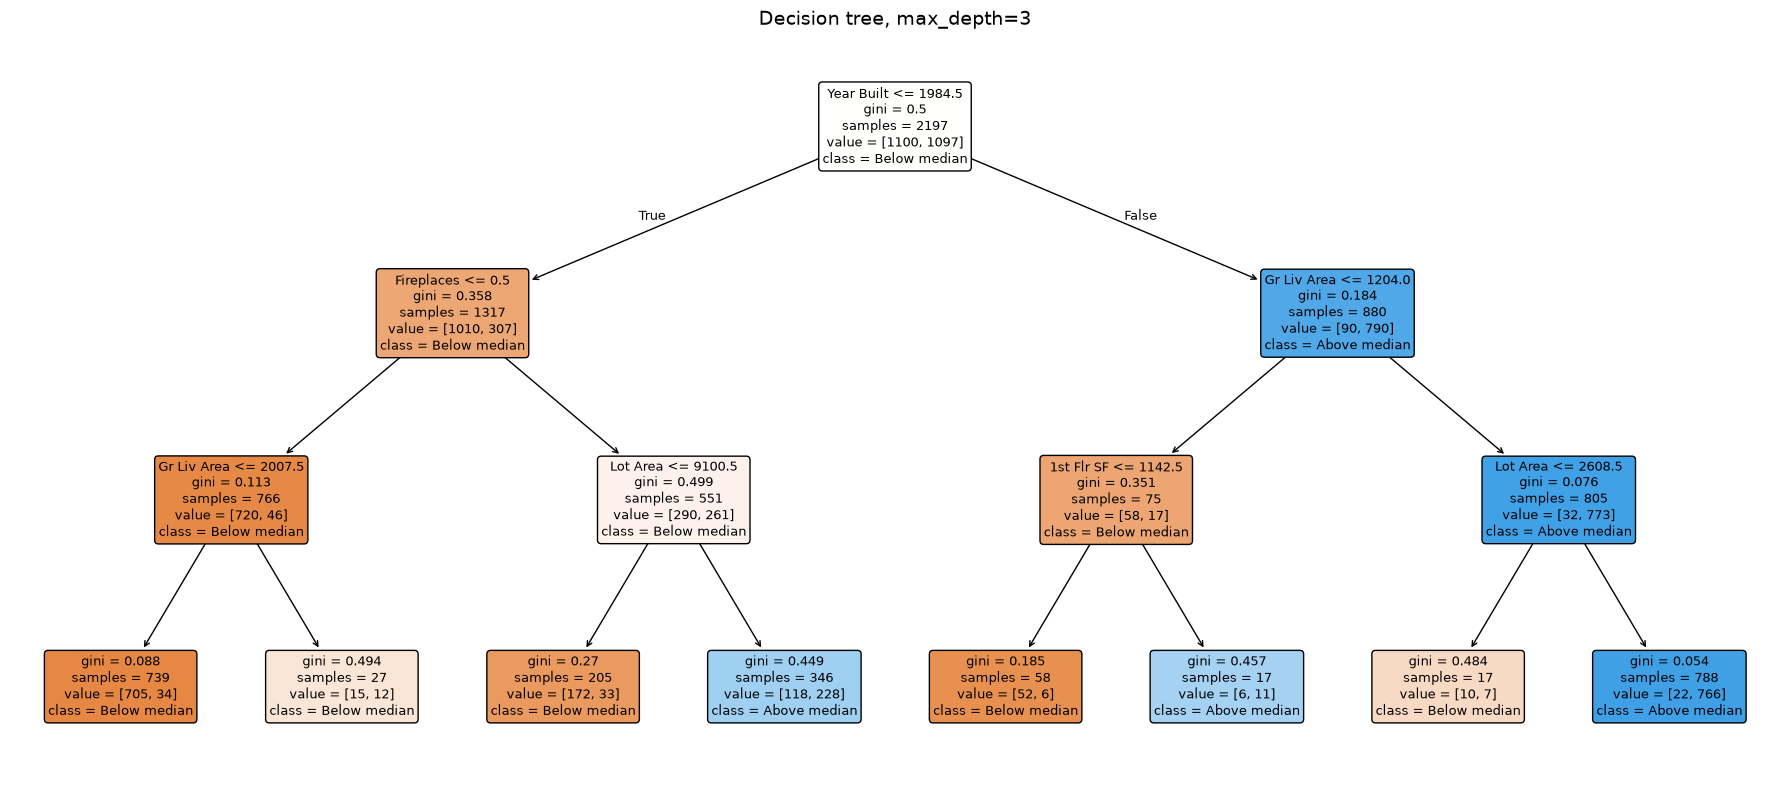

In [10]:
plt.figure(figsize=(18, 8))
plot_tree(tree,
          feature_names=X.columns,
          class_names=['Below median', 'Above median'],
          filled=True, rounded=True, fontsize=9, impurity=True)
plt.title('Decision tree, max_depth=3', fontsize=14)
plt.tight_layout()
plt.show()

### How to read a node

```
Gr Liv Area (Continuous): Above grade (ground) living area square feet

Gr Liv Area <= 1482.5      the question being asked
gini = 0.5                 how mixed this node is. 0 = pure, 0.5 = worst case
samples = 2197             how many training rows arrived here
value = [1098, 1099]       how many of each class
class = Above median       what this node would predict
```

**Left branch is True. Right branch is False.** Always.

In [11]:
# The same tree as text. Easier to quote in a report.
print(export_text(tree, feature_names=list(X.columns)))

|--- Year Built <= 1984.50
|   |--- Fireplaces <= 0.50
|   |   |--- Gr Liv Area <= 2007.50
|   |   |   |--- class: 0
|   |   |--- Gr Liv Area >  2007.50
|   |   |   |--- class: 0
|   |--- Fireplaces >  0.50
|   |   |--- Lot Area <= 9100.50
|   |   |   |--- class: 0
|   |   |--- Lot Area >  9100.50
|   |   |   |--- class: 1
|--- Year Built >  1984.50
|   |--- Gr Liv Area <= 1204.00
|   |   |--- 1st Flr SF <= 1142.50
|   |   |   |--- class: 0
|   |   |--- 1st Flr SF >  1142.50
|   |   |   |--- class: 1
|   |--- Gr Liv Area >  1204.00
|   |   |--- Lot Area <= 2608.50
|   |   |   |--- class: 0
|   |   |--- Lot Area >  2608.50
|   |   |   |--- class: 1



## 3.2 How a tree picks its splits

It tries every column and every cut point, and scores each one by **impurity**.

In [12]:
def gini(pos, total):
    if total == 0:
        return 0.0
    p = pos / total
    return 1 - (p**2 + (1-p)**2)

print('GINI IMPURITY: how mixed is this group?')
print()
print(f"{'split':>22}{'gini':>10}   meaning")
for pos, tot, label in [(50, 100, '50 / 50'), (70, 100, '70 / 30'),
                        (90, 100, '90 / 10'), (99, 100, '99 / 1'),
                        (100, 100, '100 / 0')]:
    print(f'{label:>22}{gini(pos, tot):>10.3f}   ', end='')
    print('worst possible' if pos == 50 else ('perfectly pure' if pos == tot else 'getting purer'))
print()
print('The tree picks whichever split lowers impurity the most.')

GINI IMPURITY: how mixed is this group?

                 split      gini   meaning
               50 / 50     0.500   worst possible
               70 / 30     0.420   getting purer
               90 / 10     0.180   getting purer
                99 / 1     0.020   getting purer
               100 / 0     0.000   perfectly pure

The tree picks whichever split lowers impurity the most.


---
# Section 4: Depth, Overfitting, and What the Tree Looks At

A tree will keep splitting until every leaf is pure, if you let it.

In [13]:
rows = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None]:
    m = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train, y_train)
    rows.append({
        'max_depth': 'unlimited' if d is None else d,
        'leaves': m.get_n_leaves(),
        'train acc': round(accuracy_score(y_train, m.predict(X_train)) * 100, 1),
        'test acc' : round(accuracy_score(y_test,  m.predict(X_test))  * 100, 1),
    })
depth = pd.DataFrame(rows)
depth['gap'] = (depth['train acc'] - depth['test acc']).round(1)
print(depth.to_string(index=False))

max_depth  leaves  train acc  test acc  gap
        1       2       81.9      81.4  0.5
        2       4       83.8      83.4  0.4
        3       8       89.2      87.6  1.6
        4      16       90.3      90.2  0.1
        5      31       93.4      91.3  2.1
        6      47       94.9      88.7  6.2
        8      85       97.1      88.9  8.2
       10     123       99.0      86.8 12.2
       15     142      100.0      87.2 12.8
       20     143      100.0      87.3 12.7
unlimited     143      100.0      87.3 12.7


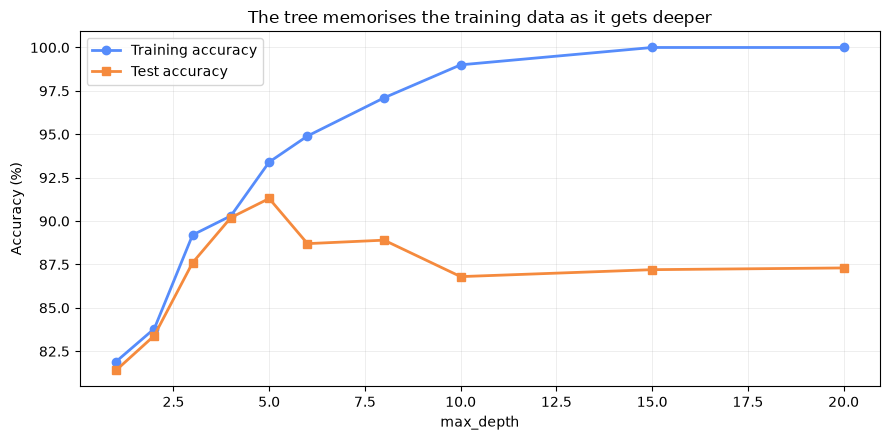

Training accuracy climbs toward 100%. Test accuracy stops improving,
then falls. The gap between the two lines IS overfitting.


In [14]:
d = depth[depth['max_depth'] != 'unlimited']
plt.figure(figsize=(9, 4.5))
plt.plot(d['max_depth'], d['train acc'], 'o-', lw=2, label='Training accuracy')
plt.plot(d['max_depth'], d['test acc'],  's-', lw=2, label='Test accuracy')
plt.xlabel('max_depth'); plt.ylabel('Accuracy (%)')
plt.title('The tree memorises the training data as it gets deeper')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print('Training accuracy climbs toward 100%. Test accuracy stops improving,')
print('then falls. The gap between the two lines IS overfitting.')

**This is the single most important plot in the lecture.** An unlimited tree gets
close to perfect on data it has already seen, and does worse on data it has not.

That is memorising, not learning.

In [15]:
# Which columns did the tree actually use?
best_depth = 5
m5 = DecisionTreeClassifier(max_depth=best_depth, random_state=SEED).fit(X_train, y_train)

imp = pd.Series(m5.feature_importances_, index=X.columns)
imp = imp[imp > 0].sort_values(ascending=False)

print(f'Tree with max_depth={best_depth} used {len(imp)} of {X.shape[1]} columns.')
print(f'It ignored {X.shape[1] - len(imp)} columns completely.')
print()
print(imp.head(12).round(4).to_string())

Tree with max_depth=5 used 14 of 36 columns.
It ignored 22 columns completely.

Year Built        0.5478
Gr Liv Area       0.1316
Fireplaces        0.1262
Lot Area          0.1037
Total Bsmt SF     0.0306
Overall Qual      0.0186
1st Flr SF        0.0125
Overall Cond      0.0107
Full Bath         0.0083
Garage Area       0.0022
BsmtFin SF 1      0.0022
Year Remod/Add    0.0020


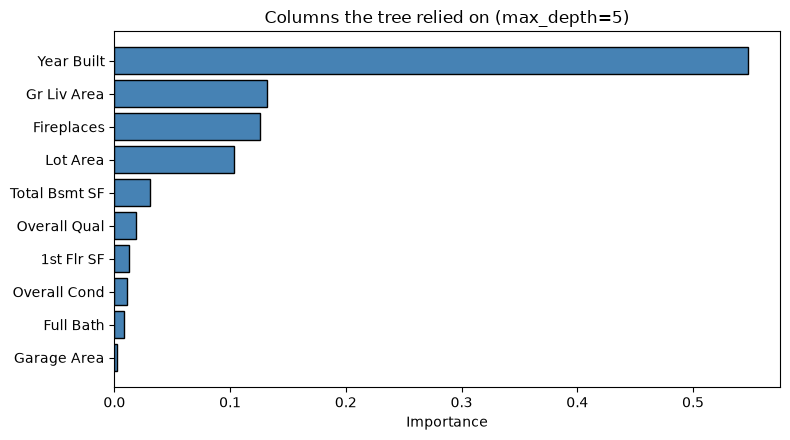

In [16]:
plt.figure(figsize=(8, 4.5))
top = imp.head(10).iloc[::-1]
plt.barh(range(len(top)), top.values, color='steelblue', edgecolor='black')
plt.yticks(range(len(top)), top.index)
plt.xlabel('Importance')
plt.title(f'Columns the tree relied on (max_depth={best_depth})')
plt.tight_layout(); plt.show()

## 4.1 Trees do not care about scaling

Direct contrast with everything from Sep 02 and Sep 09.

In [17]:
scaler = StandardScaler().fit(X_train)
Xtr_s = scaler.transform(X_train)
Xte_s = scaler.transform(X_test)

raw    = DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(X_train, y_train)
scaled = DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(Xtr_s, y_train)

print(f'Tree on raw data    : {accuracy_score(y_test, raw.predict(X_test))*100:.2f}%')
print(f'Tree on scaled data : {accuracy_score(y_test, scaled.predict(Xte_s))*100:.2f}%')
print()
print('Identical, or near enough.')
print()
print('WHY: a tree asks "is Lot Area above 9600?" It looks at ONE column at a time.')
print('It never compares Lot Area against Overall Qual, so their units never meet.')
print('k-NN and PCA compare columns to each other. That is why they need scaling.')

Tree on raw data    : 91.27%
Tree on scaled data : 91.13%

Identical, or near enough.

WHY: a tree asks "is Lot Area above 9600?" It looks at ONE column at a time.
It never compares Lot Area against Overall Qual, so their units never meet.
k-NN and PCA compare columns to each other. That is why they need scaling.


### CHECKPOINT 1

Post these numbers to the Canvas discussion.

In [18]:
print(f'Best test accuracy    : {depth["test acc"].max()}%')
print(f'At max_depth          : {depth.loc[depth["test acc"].idxmax(), "max_depth"]}')
print(f'Unlimited tree, train : {depth.iloc[-1]["train acc"]}%')
print(f'Unlimited tree, test  : {depth.iloc[-1]["test acc"]}%')

Best test accuracy    : 91.3%
At max_depth          : 5
Unlimited tree, train : 100.0%
Unlimited tree, test  : 87.3%


---
# Section 7: Naive Bayes on Ames

A completely different idea. Instead of asking questions, work out which class
is more **probable** given the evidence.

In [19]:
nb = GaussianNB()
nb.fit(X_train, y_train)

nb_acc = accuracy_score(y_test, nb.predict(X_test))
print(f'Naive Bayes test accuracy : {nb_acc*100:.1f}%')
print(f'Decision tree (depth 5)   : {accuracy_score(y_test, m5.predict(X_test))*100:.1f}%')
print(f'Baseline                  : {baseline*100:.1f}%')

Naive Bayes test accuracy : 91.1%
Decision tree (depth 5)   : 91.3%
Baseline                  : 50.1%


## 7.1 What the model actually stores

A tree stores questions. Naive Bayes stores **probabilities**.

In [20]:
print('CLASS PRIORS: how common is each class before you look at anything?')
for cls, p in zip(nb.classes_, nb.class_prior_):
    name = 'Below median' if cls == 0 else 'Above median'
    print(f'   {name:14s} {p*100:.1f}%')
print()
print('That is all it knows before seeing a single feature.')

CLASS PRIORS: how common is each class before you look at anything?
   Below median   50.1%
   Above median   49.9%

That is all it knows before seeing a single feature.


In [21]:
# What it learned about each column, inside each class
theta = pd.DataFrame(nb.theta_, columns=X.columns,
                     index=['Below median', 'Above median']).T
theta['difference'] = (theta['Above median'] - theta['Below median']).abs()

print('Average value of each column, per class. Biggest differences first:')
print(theta.sort_values('difference', ascending=False).head(10).round(1).to_string())
print()
print('Columns where the two classes differ most are the ones doing the work.')

Average value of each column, per class. Biggest differences first:
               Below median  Above median  difference
Lot Area             8576.1       11602.7      3026.6
Gr Liv Area          1212.6        1781.8       569.2
Total Bsmt SF         853.3        1253.7       400.4
1st Flr SF            988.2        1325.1       336.9
2nd Flr SF            217.9         454.7       236.9
Garage Area           361.9         580.2       218.3
BsmtFin SF 1          338.0         555.1       217.0
Bsmt Unf SF           462.9         649.5       186.6
Mas Vnr Area           47.2         160.7       113.5
Wood Deck SF           56.7         129.8        73.1

Columns where the two classes differ most are the ones doing the work.


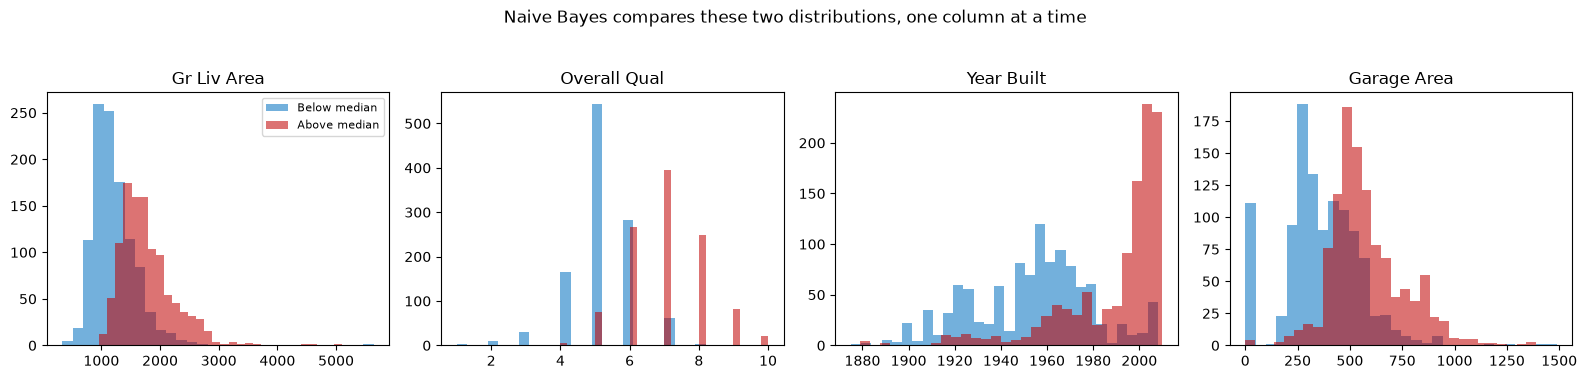

Where the red and blue barely overlap, that column separates the classes well.
Where they sit on top of each other, the column tells you nothing.


In [22]:
# Draw the two distributions it is comparing
cols = ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Garage Area']
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, c in zip(ax, cols):
    for cls, lab, col in [(0, 'Below median', '#0070C0'), (1, 'Above median', '#C00000')]:
        a.hist(X_train.loc[y_train == cls, c], bins=30, alpha=.55, label=lab, color=col)
    a.set_title(c); a.set_xlabel('')
ax[0].legend(fontsize=8)
plt.suptitle('Naive Bayes compares these two distributions, one column at a time', y=1.04)
plt.tight_layout(); plt.show()

print('Where the red and blue barely overlap, that column separates the classes well.')
print('Where they sit on top of each other, the column tells you nothing.')

## 7.2 Seeing a single prediction

Take one house and watch the model decide.

In [23]:
i = 0
row = X_test.iloc[[i]]
prob = nb.predict_proba(row)[0]

print('House being classified:')
print(row.T.head(8).to_string(header=False))
print()
print(f'P(Below median) = {prob[0]:.4f}')
print(f'P(Above median) = {prob[1]:.4f}')
print(f'Prediction      = {"Above median" if prob[1] > prob[0] else "Below median"}')
print(f'Truth           = {"Above median" if y_test.iloc[i] == 1 else "Below median"}')
print()
print('The two probabilities always add to 1. The model picks the larger one.')

House being classified:
MS SubClass       50.0
Lot Frontage      52.0
Lot Area        9439.0
Overall Qual       5.0
Overall Cond       5.0
Year Built      1930.0
Year Remod/Add  1950.0
Mas Vnr Area       0.0

P(Below median) = 1.0000
P(Above median) = 0.0000
Prediction      = Below median
Truth           = Below median

The two probabilities always add to 1. The model picks the larger one.


---
# Section 8: The Word "Naive"

Naive Bayes multiplies the per-column probabilities together. That is only valid
if the columns are **independent of each other**.

Ames columns are not independent at all.

In [24]:
corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

pairs = upper.stack().sort_values(ascending=False).head(12).reset_index()
pairs.columns = ['column A', 'column B', 'correlation']

print('The most correlated pairs in the data we just fed to naive Bayes:')
print(pairs.round(3).to_string(index=False))
print()
n_bad = int((upper > 0.7).sum().sum())
print(f'Pairs correlating above 0.7 : {n_bad}')
print()
print('Naive Bayes assumed every one of these pairs was independent.')
print('It counted the same evidence twice, and became overconfident.')

The most correlated pairs in the data we just fed to naive Bayes:
      column A       column B  correlation
   Garage Cars    Garage Area        0.885
 Total Bsmt SF     1st Flr SF        0.833
   Gr Liv Area  TotRms AbvGrd        0.811
    Year Built  Garage Yr Blt        0.790
 Bedroom AbvGr  TotRms AbvGrd        0.668
    2nd Flr SF    Gr Liv Area        0.642
  BsmtFin SF 1 Bsmt Full Bath        0.640
   Gr Liv Area      Full Bath        0.636
    2nd Flr SF      Half Bath        0.616
  Overall Qual     Year Built        0.609
Year Remod/Add  Garage Yr Blt        0.609
    Year Built Year Remod/Add        0.602

Pairs correlating above 0.7 : 4

Naive Bayes assumed every one of these pairs was independent.
It counted the same evidence twice, and became overconfident.


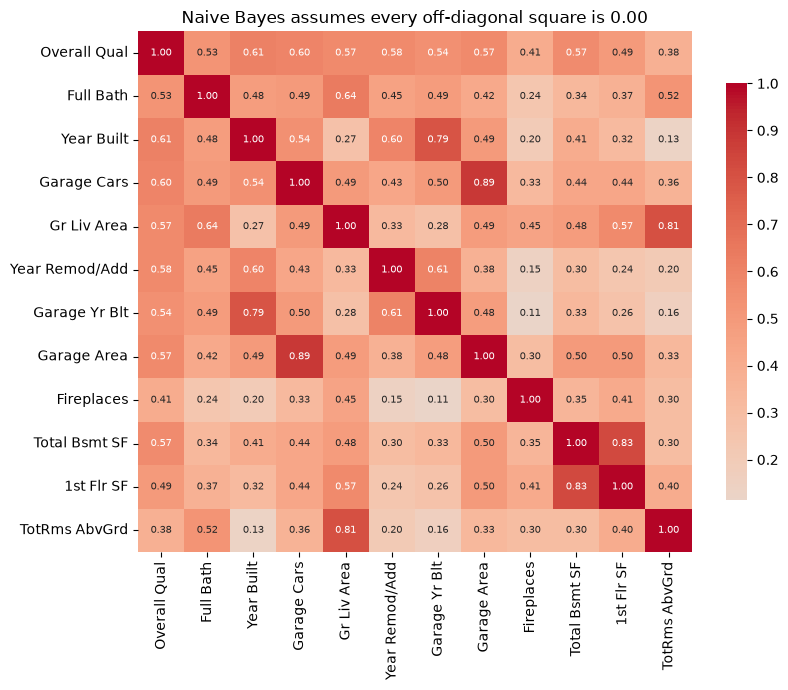

Every dark square off the diagonal is a broken assumption.


In [25]:
plt.figure(figsize=(8.5, 7))
top = X_train.corrwith(y_train).abs().sort_values(ascending=False).head(12).index
sns.heatmap(X_train[top].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, annot_kws={'size': 7}, cbar_kws={'shrink': .8})
plt.title('Naive Bayes assumes every off-diagonal square is 0.00')
plt.tight_layout(); plt.show()

print('Every dark square off the diagonal is a broken assumption.')

In [26]:
# Does removing the duplicates help?
drop = [c for c in upper.columns if any(upper[c] > 0.7)]
Xtr_ind = X_train.drop(columns=drop)
Xte_ind = X_test.drop(columns=drop)

nb_ind = GaussianNB().fit(Xtr_ind, y_train)

print(f'Columns dropped for being correlated : {len(drop)}')
print()
print(f'Naive Bayes, all {X_train.shape[1]} columns        : '
      f'{accuracy_score(y_test, nb.predict(X_test))*100:.1f}%')
print(f'Naive Bayes, {Xtr_ind.shape[1]} less-correlated columns : '
      f'{accuracy_score(y_test, nb_ind.predict(Xte_ind))*100:.1f}%')
print()
print('Did it help, or hurt? Look at the two numbers before you decide.')
print()
print('Two things are fighting each other here:')
print('  - Removing correlated columns moves you CLOSER to the independence assumption.')
print('  - But every column you drop is information the model no longer has.')
print('Which effect wins is an empirical question, not something you can reason out.')

Columns dropped for being correlated : 4

Naive Bayes, all 36 columns        : 91.1%
Naive Bayes, 32 less-correlated columns : 91.0%

Did it help, or hurt? Look at the two numbers before you decide.

Two things are fighting each other here:
  - Removing correlated columns moves you CLOSER to the independence assumption.
  - But every column you drop is information the model no longer has.
Which effect wins is an empirical question, not something you can reason out.


## 8.1 The second assumption: normality

`GaussianNB` assumes each column follows a bell curve inside each class.
Ames columns are skewed. You proved that on Aug 31.

In [27]:
skew = X_train.skew().abs().sort_values(ascending=False)
print('Most skewed columns (0 would be a perfect bell curve):')
print(skew.head(8).round(2).to_string())
print()
print(f'Columns with |skew| > 2 : {(skew > 2).sum()} of {len(skew)}')

Most skewed columns (0 would be a perfect bell curve):
Misc Val           22.36
Pool Area          21.17
Lot Area           14.06
Low Qual Fin SF    13.36
3Ssn Porch         12.02
Enclosed Porch      4.26
Kitchen AbvGr       4.24
BsmtFin SF 2        4.16

Columns with |skew| > 2 : 12 of 36


In [28]:
# Log transform the skewed columns and refit
Xtr_log = X_train.copy()
Xte_log = X_test.copy()
skewed = skew[skew > 1].index
for c in skewed:
    Xtr_log[c] = np.log1p(Xtr_log[c].clip(lower=0))
    Xte_log[c] = np.log1p(Xte_log[c].clip(lower=0))

nb_log = GaussianNB().fit(Xtr_log, y_train)

print(f'Columns log transformed : {len(skewed)}')
print()
print(f'Naive Bayes, raw           : {accuracy_score(y_test, nb.predict(X_test))*100:.1f}%')
print(f'Naive Bayes, log corrected : {accuracy_score(y_test, nb_log.predict(Xte_log))*100:.1f}%')
print()
print('Report what you actually see, not what you expected.')
print()
print('GaussianNB assumes a bell curve, so in principle fixing skew should help it.')
print('In practice the gain is often small, because the skewed columns may not have')
print('been the ones carrying the signal.')
print()
print('What is certain: this transform would do NOTHING at all for a decision tree.')
print('A tree only cares about the ORDER of values, and log preserves order exactly.')

Columns log transformed : 19

Naive Bayes, raw           : 91.1%
Naive Bayes, log corrected : 89.5%

Report what you actually see, not what you expected.

GaussianNB assumes a bell curve, so in principle fixing skew should help it.
In practice the gain is often small, because the skewed columns may not have
been the ones carrying the signal.

What is certain: this transform would do NOTHING at all for a decision tree.
A tree only cares about the ORDER of values, and log preserves order exactly.
